# Chapter 14 · American options by simulation: interactive demos

Companion to Chapter 14 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/14-american-mc.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The running example is the put of Longstaff and Schwartz (2001): $K=40$, $r=6\%$, $y=0$, $50$ exercise dates per
year. Prices without simulation come from the grid of Remark 14.4 (`bermudan_grid`, `bermudan_reference`) and the
smoothed binomial tree (`american_binomial`). Everything is discounted to time $0$ unless a plot says otherwise.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d.american import (american_binomial, andersen_broadie, bermudan_grid, bermudan_reference,
                              cash_flows_at, discounted_payoffs, dual_samples, european_martingale,
                              grid_doob_martingale, laguerre_basis, lsm_boundary, lsm_fit, policy_cashflows,
                              policy_grid, policy_martingale, poly_basis, put_payoff, simulate)
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN, PURPLE = "#1BAF7A", "#6250D6"
K, R = 40.0, 0.06

def make_basis(name, K=K):
    if name == "Laguerre (LS)":
        return laguerre_basis(3, scale=K)
    return poly_basis(int(name.split()[-1]), scale=K)

BASES = ["Laguerre (LS)", "monomials 1", "monomials 2", "monomials 3", "monomials 5", "monomials 8"]

## 1. One regression of the Longstaff–Schwartz algorithm

At date $t_k$ the algorithm regresses the realised discounted cash flows of the in-the-money paths on basis functions
of $S_{t_k}$ (step (2) of Section 14.2). The plot shows the cash flows minus the exercise value $K-s$, the fitted
continuation value and the exact one from the grid, all in time-$t_k$ units: the rule exercises where the fitted
curve is below zero. The title gives the in-sample estimate, the exact value of the fitted policy (computed on the
grid) and the Bermudan price.

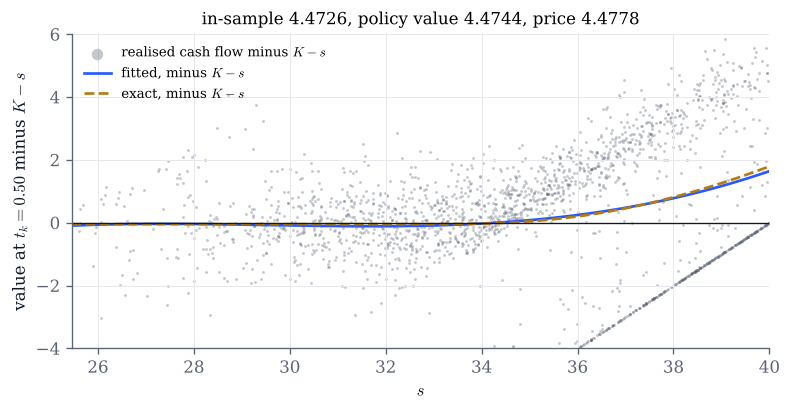

In [2]:
def regression(k=25, n_paths=20_000, basis_name="Laguerre (LS)", S0=36.0, sigma=0.2, seed=0):
    T, m = 1.0, 50
    g = put_payoff(K)
    basis = make_basis(basis_name)
    det = bermudan_grid(S0, K, T, R, 0.0, sigma, m, h=1e-3, details=True)
    train = simulate(S0, T, m, R, 0.0, sigma, n_paths, seed=seed)
    fit = lsm_fit(train, g, basis, R, T)
    value = policy_grid(fit, basis, S0, K, T, R, 0.0, sigma, h=1e-3)["price"]
    tk = det["t"][k]
    Y = cash_flows_at(train, fit, g, basis, k)
    Sk = train[:, k]
    itm = np.flatnonzero(Sk < K)
    pick = np.random.default_rng(1).choice(itm, min(2000, itm.size), replace=False)
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.scatter(Sk[pick], np.exp(R * tk) * Y[pick] - (K - Sk[pick]), s=3, color=GREY, alpha=0.35, lw=0,
               label="realised cash flow minus $K-s$")
    lo = np.quantile(Sk[itm], 0.005)
    sg = np.linspace(lo, K, 300)
    if fit["coefs"][k] is not None:
        ax.plot(sg, np.exp(R * tk) * (basis(sg) @ fit["coefs"][k]) - (K - sg), color=COBALT, label="fitted, minus $K-s$")
    ax.plot(det["s"], det["C"][k] - (K - det["s"]), color=GOLD, ls="--", label="exact, minus $K-s$")
    ax.axhline(0, color=INK, lw=0.8)
    ax.set(xlim=(lo, K), ylim=(-4, 6), xlabel="$s$", ylabel=f"value at $t_k={tk:.2f}$ minus $K-s$",
           title=f"in-sample {fit['value']:.4f}, policy value {value:.4f}, price {det['price']:.4f}")
    ax.legend(fontsize=8, loc="upper left", markerscale=4)
    plt.show()

regression()

In [3]:
# Explore: few paths, many basis functions, dates near maturity.
interact(regression,
         k=IntSlider(value=25, min=1, max=49, continuous_update=False, description="date k"),
         n_paths=IntSlider(value=20_000, min=200, max=100_000, step=200, continuous_update=False, description="paths"),
         basis_name=Dropdown(options=BASES, value="Laguerre (LS)", description="basis"),
         S0=FloatSlider(value=36, min=30, max=46, step=1, continuous_update=False, description="S0"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="sigma"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 2. In sample and out of sample

Proposition 14.6: the out-of-sample estimator is biased low (its conditional mean is the value of the fitted policy,
at most the price), while the in-sample estimate has no such guarantee; with few paths and many basis functions the
paths' own futures leak into their exercise decisions, and it is biased high. Each dot below is one independent
training set: its in-sample estimate and the exact value of its policy.

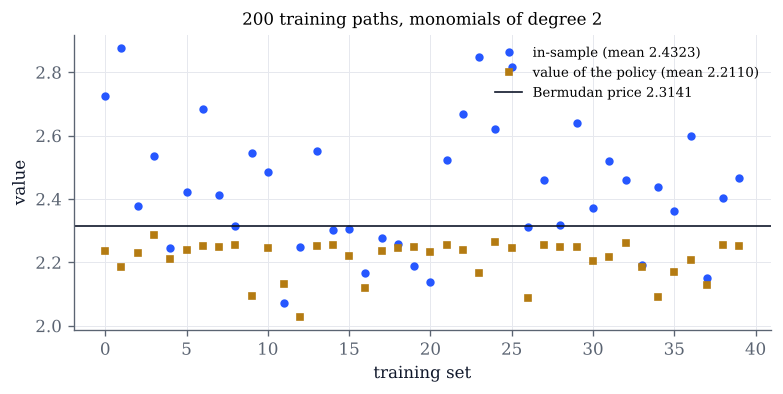

In [4]:
def in_out(n_paths=200, basis_name="monomials 2", reps=40, S0=40.0, sigma=0.2, seed=0):
    T, m = 1.0, 50
    g = put_payoff(K)
    basis = make_basis(basis_name)
    price = bermudan_reference(S0, K, T, R, 0.0, sigma, m, h=2e-3)
    ins, pol = [], []
    for j in range(reps):
        fit = lsm_fit(simulate(S0, T, m, R, 0.0, sigma, n_paths, seed=[seed, j]), g, basis, R, T)
        ins.append(fit["value"])
        pol.append(policy_grid(fit, basis, S0, K, T, R, 0.0, sigma, h=2e-3)["price"])
    ins, pol = np.array(ins), np.array(pol)
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.plot(ins, "o", color=COBALT, ms=4, label=f"in-sample (mean {ins.mean():.4f})")
    ax.plot(pol, "s", color=GOLD, ms=4, label=f"value of the policy (mean {pol.mean():.4f})")
    ax.axhline(price, color=INK, lw=1, label=f"Bermudan price {price:.4f}")
    ax.set(xlabel="training set", ylabel="value", title=f"{n_paths} training paths, {basis.label}")
    ax.legend(fontsize=8)
    plt.show()

in_out()

In [5]:
# Explore: the in-sample bias changes sign as the number of paths grows; the policy values never exceed the price.
interact(in_out,
         n_paths=IntSlider(value=200, min=50, max=20_000, step=50, continuous_update=False, description="paths"),
         basis_name=Dropdown(options=BASES, value="monomials 2", description="basis"),
         reps=IntSlider(value=40, min=10, max=200, step=10, continuous_update=False, description="training sets"),
         S0=FloatSlider(value=40, min=32, max=46, step=1, continuous_update=False, description="S0"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="sigma"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 3. Exercise boundaries

The critical price $b(t_k)$ below which the put is exercised, from the grid and from the fitted policy (the largest
price at which it exercises). Near maturity few paths are close to the boundary, and the fit has little to go on.
The policy value in the title is computed exactly on the grid.

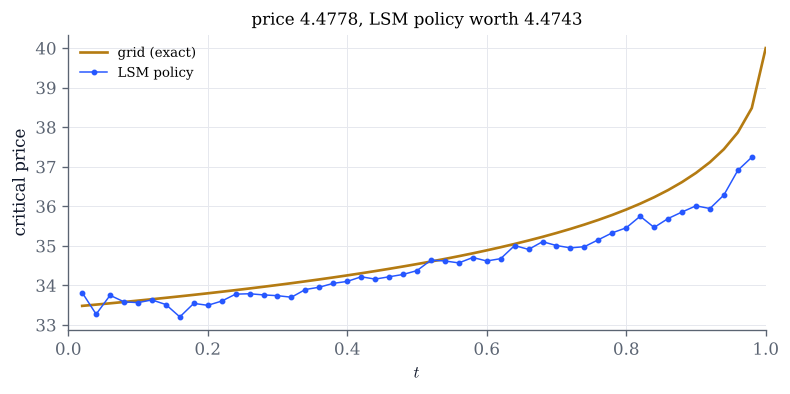

In [6]:
def boundary(n_paths=50_000, basis_name="Laguerre (LS)", sigma=0.2, r=0.06, T=1.0, S0=36.0, seed=0):
    m = int(round(50 * T))
    g = put_payoff(K)
    basis = make_basis(basis_name)
    det = bermudan_grid(S0, K, T, r, 0.0, sigma, m, h=1e-3, details=True)
    fit = lsm_fit(simulate(S0, T, m, r, 0.0, sigma, n_paths, seed=seed), g, basis, r, T)
    value = policy_grid(fit, basis, S0, K, T, r, 0.0, sigma, h=1e-3)["price"]
    b = lsm_boundary(fit, g, basis, np.linspace(1.0, K, 4001))
    t = det["t"]
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.plot(t[1:], det["boundary"][1:], color=GOLD, label="grid (exact)")
    ax.plot(t[1:m], b[1:m], "o-", color=COBALT, ms=2.5, lw=0.9, label="LSM policy")
    ax.set(xlabel="$t$", ylabel="critical price", xlim=(0, T),
           title=f"price {det['price']:.4f}, LSM policy worth {value:.4f}")
    ax.legend(fontsize=8)
    plt.show()

boundary()

In [7]:
interact(boundary,
         n_paths=IntSlider(value=50_000, min=1_000, max=200_000, step=1_000, continuous_update=False, description="paths"),
         basis_name=Dropdown(options=BASES, value="Laguerre (LS)", description="basis"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="sigma"),
         r=FloatSlider(value=0.06, min=0.01, max=0.12, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.5, max=2.0, step=0.5, continuous_update=False, description="T"),
         S0=FloatSlider(value=36, min=30, max=46, step=1, continuous_update=False, description="S0"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 4. Upper bounds by duality

Theorem 14.10: for every martingale $M$ with $M_0=0$, $\mathbb E[\max_k(Z_k-M_k)]$ is at least the price, with
equality, path by path, for the Doob martingale $M^*$ of the Snell envelope. The empirical distributions of
$\max_k(Z_k-M_k)$ below are for the European put martingale (closed form), the Andersen–Broadie martingale of an LSM
policy estimated by nested simulation (Proposition 14.11), the same martingale with exact continuation values, and
$M^*$ from the grid. Perfect foresight ($M=0$) is printed only: it is far to the right. The nested estimator is
expensive: its cost grows like (outer paths) × (inner paths) × $m^2$.

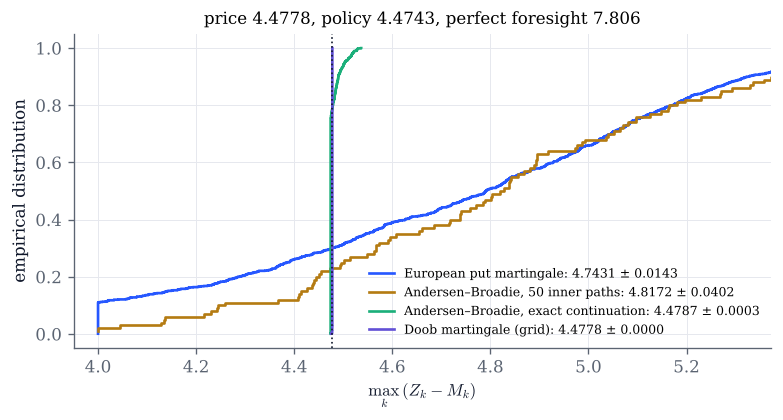

In [8]:
def duality(S0=36.0, sigma=0.2, n_outer=1000, n_nested=100, n_inner=50, seed=0):
    T, m = 1.0, 50
    g = put_payoff(K)
    basis = laguerre_basis(3, scale=K)
    det = bermudan_grid(S0, K, T, R, 0.0, sigma, m, h=1e-3, details=True)
    fit = lsm_fit(simulate(S0, T, m, R, 0.0, sigma, 50_000, seed=[seed, 0]), g, basis, R, T)
    pol = policy_grid(fit, basis, S0, K, T, R, 0.0, sigma, h=1e-3)
    outer = simulate(S0, T, m, R, 0.0, sigma, n_outer, seed=[seed, 1])
    Z = discounted_payoffs(outer, g, R, T)
    samples = {
        "European put martingale": dual_samples(Z, european_martingale(outer, K, T, R, 0.0, sigma, "put")),
        f"Andersen–Broadie, {n_inner} inner paths": andersen_broadie(outer[:n_nested], fit, g, basis, 0.0, sigma,
                                                                    n_inner, seed=[seed, 2])["samples"],
        "Andersen–Broadie, exact continuation": dual_samples(Z, policy_martingale(outer, fit, g, basis, pol)),
        "Doob martingale (grid)": dual_samples(Z, grid_doob_martingale(outer, det, R)),
    }
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    for (name, v), color in zip(samples.items(), (COBALT, GOLD, GREEN, PURPLE)):
        v = np.sort(v)
        se = v.std(ddof=1) / np.sqrt(v.size)
        ax.step(v, np.arange(1, v.size + 1) / v.size, where="post", color=color,
                label=f"{name}: {v.mean():.4f} ± {se:.4f}")
    ax.axvline(det["price"], color=INK, ls=":", lw=1)
    pf = Z.max(axis=1).mean()
    ax.set(xlabel="$\\max_k (Z_k - M_k)$", ylabel="empirical distribution",
           title=f"price {det['price']:.4f}, policy {pol['price']:.4f}, perfect foresight {pf:.3f}")
    lo, hi = np.quantile(np.concatenate(list(samples.values())), [0.01, 0.97])
    ax.set_xlim(min(lo, det["price"]) - 0.05, hi)
    ax.legend(fontsize=7.5, loc="lower right")
    plt.show()

duality()

In [9]:
# Explore: more inner paths shrink the upward bias of the nested estimator; the cost grows quickly.
interact(duality,
         S0=FloatSlider(value=36, min=30, max=46, step=1, continuous_update=False, description="S0"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="sigma"),
         n_outer=IntSlider(value=1000, min=200, max=5000, step=100, continuous_update=False, description="outer"),
         n_nested=IntSlider(value=100, min=20, max=500, step=20, continuous_update=False, description="nested outer"),
         n_inner=IntSlider(value=50, min=10, max=500, step=10, continuous_update=False, description="inner"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 5. From Bermudan to American

Proposition 14.3: the Bermudan price increases with the set of exercise dates and tends to the American price as
the dates fill $[0,T]$. The grid gives Bermudan prices for any number $m$ of equally spaced dates; the American
price comes from the smoothed binomial tree.

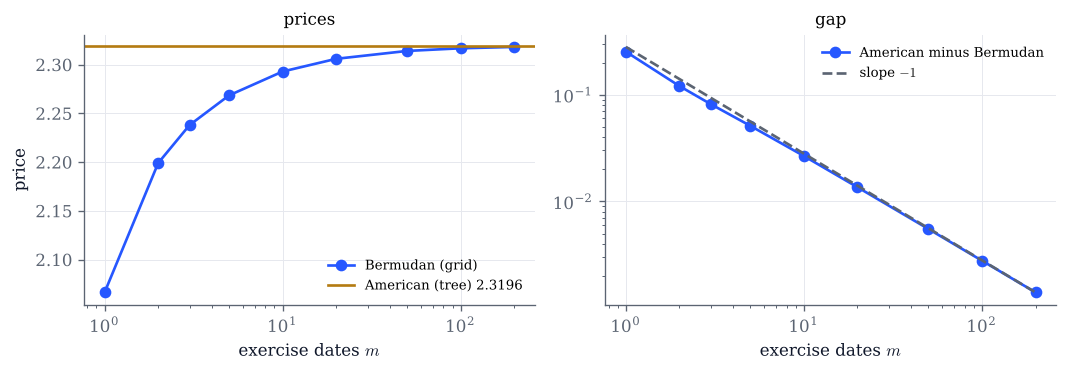

In [10]:
def bermudan_to_american(S0=40.0, sigma=0.2, r=0.06, T=1.0):
    ms = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200])
    b = np.array([bermudan_reference(S0, K, T, r, 0.0, sigma, int(mm), h=2e-3) for mm in ms])
    a = american_binomial(S0, K, T, r, 0.0, sigma, n=2000)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(9, 3.2))
    ax.plot(ms, b, "o-", color=COBALT, label="Bermudan (grid)")
    ax.axhline(a, color=GOLD, label=f"American (tree) {a:.4f}")
    ax.set(xscale="log", xlabel="exercise dates $m$", ylabel="price", title="prices")
    ax.legend(fontsize=8)
    bx.loglog(ms, a - b, "o-", color=COBALT, label="American minus Bermudan")
    bx.loglog(ms, (a - b)[-1] * ms[-1] / ms, color=GREY, ls="--", label="slope $-1$")
    bx.set(xlabel="exercise dates $m$", title="gap")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

bermudan_to_american()

In [11]:
interact(bermudan_to_american,
         S0=FloatSlider(value=40, min=30, max=50, step=1, continuous_update=False, description="S0"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="sigma"),
         r=FloatSlider(value=0.06, min=0.01, max=0.12, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.25, max=2.0, step=0.25, continuous_update=False, description="T"));

## Things to try

- In section 1, take $N=500$ paths and the monomials of degree 8. Look at dates close to maturity: where does the
  fitted curve cross zero, and what does that do to the policy value?
- In section 2, find the number of paths at which the mean in-sample estimate crosses the price, for two bases.
  Do the policy values ever exceed the price?
- In section 3, raise $\sigma$ and $T$. Where are the LSM boundaries least accurate, and why does it cost so little?
- In section 4, increase the inner paths from 10 to 500 with the outer paths fixed. How does the Andersen–Broadie
  estimate move, and how does its standard error compare with the distance to the exact-continuation bound?
- In section 5, compare $T=0.25$ and $T=2$: does the gap between the Bermudan price with $m=50$ and the American
  price depend on the spacing of the dates only, or also on the maturity?